# Building a CNN Model for Image Classification

In [1]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
import numpy as np
import os

In [2]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANNELS = 3


# Data Understanding and Preprocessing

In [3]:
#Load the dataset and explore its structure (number of classes, sample images, image sizes).

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification


In [5]:

os.listdir(path)

['seg_train', 'seg_pred', 'seg_test']

In [6]:
train_path = os.path.join(path, "seg_train", "seg_train")
test_path = os.path.join(path, "seg_test", "seg_test")

print("Training path:", train_path)
print("Testing path:", test_path)

Training path: /kaggle/input/intel-image-classification/seg_train/seg_train
Testing path: /kaggle/input/intel-image-classification/seg_test/seg_test


In [7]:
#Check the classes
print(os.listdir(train_path))

['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']


Perform data preprocessing steps:

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (150, 150)
BATCH_SIZE = 32

# Training data: normalization + augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20,

    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.20,
    horizontal_flip=True
)

# Training data
train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True
)

Found 11230 images belonging to 6 classes.


In [9]:
# Validation data: normalization only
validation_datagen = ImageDataGenerator(rescale=1./255,validation_split=0.20)

validation_data = validation_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

Found 2804 images belonging to 6 classes.


In [10]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (150, 150)
BATCH_SIZE = 32

test_datagen = ImageDataGenerator(rescale=1./255)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 3000 images belonging to 6 classes.


# Part B: CNN Model Development

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models

In [12]:
from tensorflow.keras import layers, models

model = models.Sequential([

    # Input layer
    layers.Input(shape=(150, 150, 3)),

    # Convolutional Layer 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Layer 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Layer 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Fully connected part
    layers.Flatten(),
    layers.Dense(128, activation='relu'),

    # Dropout for regularization
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(6, activation='softmax')
])

In [13]:
#Display Model Summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
#Compile the CNN
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [15]:
#Train the CNN
#Early Stopping
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [16]:
#Model Checkpointing
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint(
    "best_cnn_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

In [17]:
#Train the Model

In [18]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=30,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 153s 418ms/step - accuracy: 0.5379 - loss: 1.1709 - val_accuracy: 0.6751 - val_loss: 0.8507
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 84s 238ms/step - accuracy: 0.6651 - loss: 0.8981 - val_accuracy: 0.7400 - val_loss: 0.7044
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 85s 241ms/step - accuracy: 0.7098 - loss: 0.8054 - val_accuracy: 0.7850 - val_loss: 0.6164
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 85s 241ms/step - accuracy: 0.7374 - loss: 0.7417 - val_accuracy: 0.7953 - val_loss: 0.5735
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 86s 244ms/step - accuracy: 0.7557 - loss: 0.7039 - val_accuracy: 0.8039 - val_loss: 0.5538
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 85s 243ms/step - accuracy: 0.7607 - loss: 0.6601 - val_accuracy: 0.8110 - val_loss: 0.5707
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 86s 245ms/step - accuracy: 0.7789 - loss: 0.6263 - val_accuracy: 0.8210 - val_loss: 0.4988
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 84s 240ms/step - accuracy: 0.7816 - loss: 

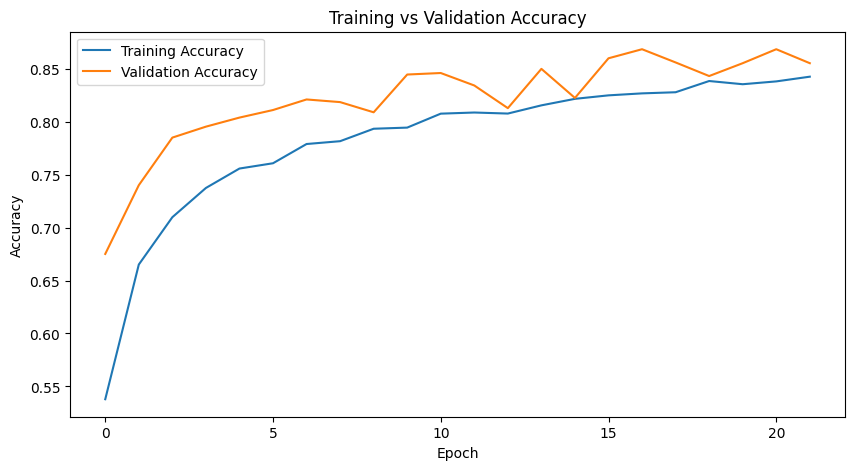

In [19]:
#Plot Training vs Validation Accuracy
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')

plt.legend()
plt.show()

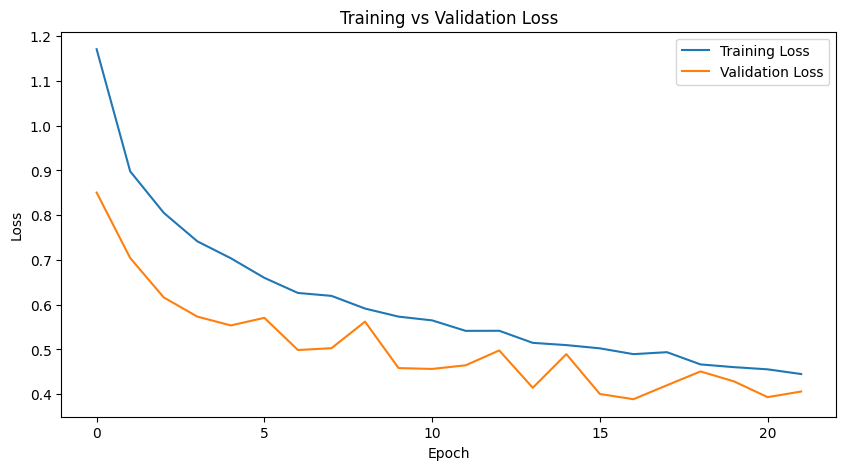

In [20]:
#Plot Training vs Validation Loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')

plt.legend()
plt.show()

# Part C: Model Evaluation and Interpretation

In [21]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 18s 189ms/step - accuracy: 0.8597 - loss: 0.4031
Test Loss: 0.4031471014022827
Test Accuracy: 0.859666645526886


In [22]:
#Generate Predictions
import numpy as np

predictions = model.predict(test_data)

predicted_classes = np.argmax( predictions,axis=1)

true_classes = test_data.classes

94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step


In [23]:
class_names = list(test_data.class_indices.keys())

print(class_names)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [24]:
#Classification Report
from sklearn.metrics import classification_report
print(
    classification_report(
        true_classes,
        predicted_classes,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

   buildings       0.85      0.85      0.85       437
      forest       0.97      0.96      0.97       474
     glacier       0.81      0.84      0.82       553
    mountain       0.79      0.81      0.80       525
         sea       0.91      0.79      0.85       510
      street       0.85      0.91      0.88       501

    accuracy                           0.86      3000
   macro avg       0.86      0.86      0.86      3000
weighted avg       0.86      0.86      0.86      3000



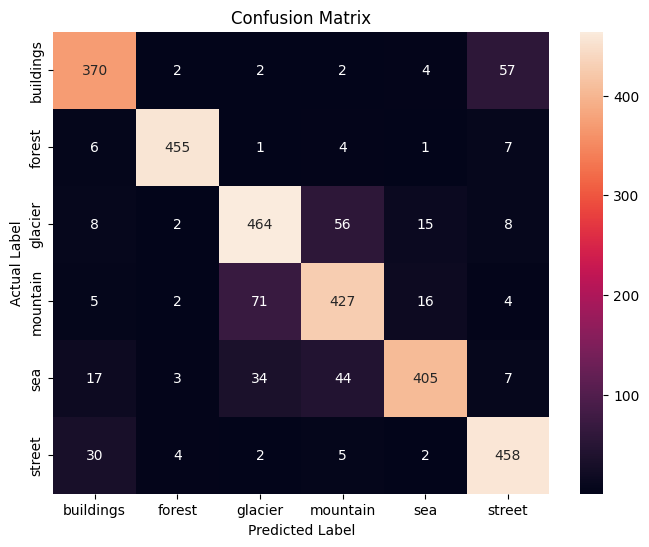

In [25]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    true_classes,
    predicted_classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')

plt.show()

In [26]:
#Visualize 10 Random Test Images
import os

test_image_paths = []

for class_name in class_names:

    class_path = os.path.join(
        test_path,
        class_name
    )

    for image_name in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            image_name
        )

        test_image_paths.append(image_path)

In [27]:
np.random.seed(42)

random_indices = np.random.choice(
    len(test_image_paths),
    10,
    replace=False
)

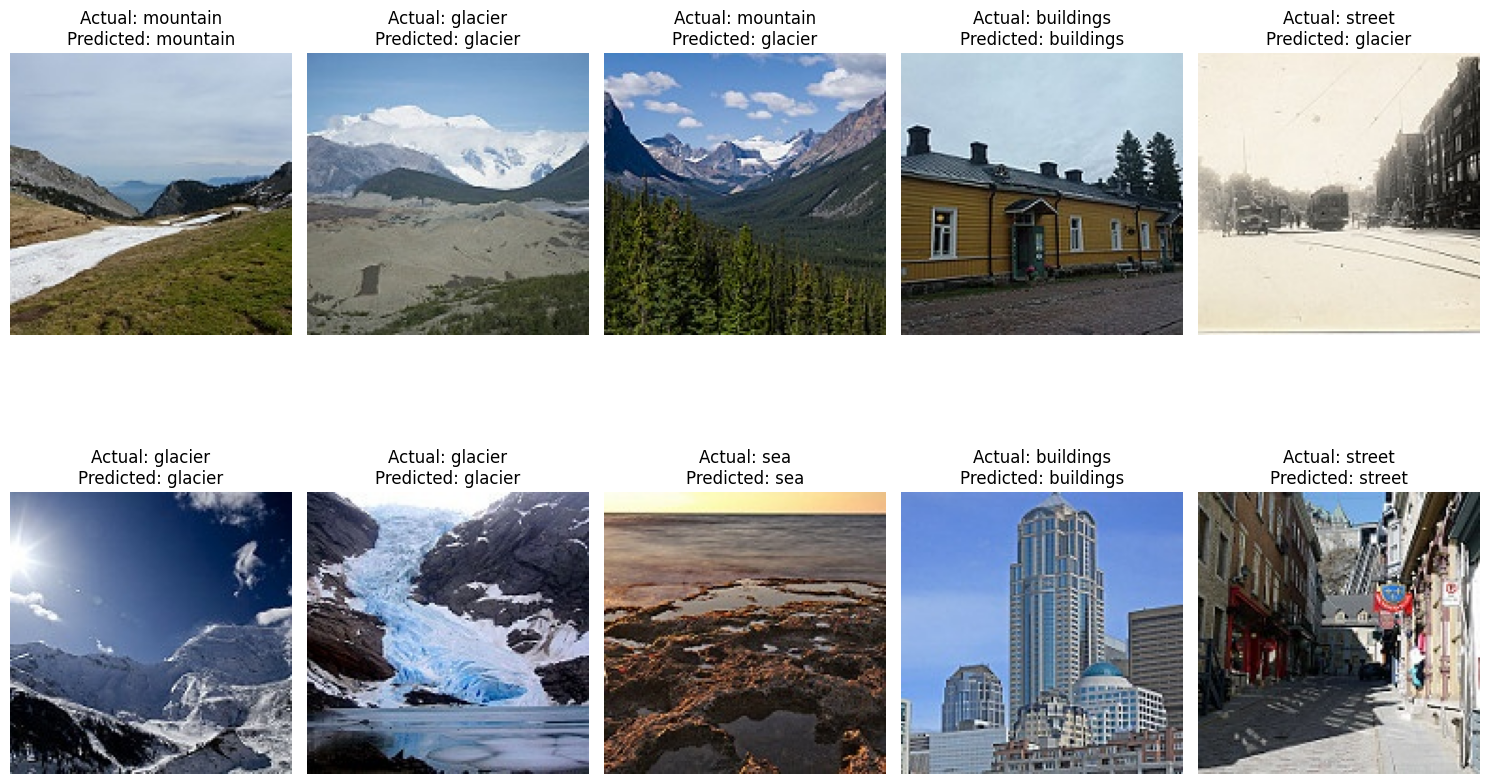

In [28]:
plt.figure(figsize=(15, 10))

for i, idx in enumerate(random_indices):

    image_path = test_image_paths[idx]

    image = tf.keras.utils.load_img(
        image_path,
        target_size=(150, 150)
    )

    image_array = tf.keras.utils.img_to_array(image)

    image_array = image_array / 255.0

    prediction = model.predict(
        np.expand_dims(image_array, axis=0),
        verbose=0
    )

    predicted_index = np.argmax(prediction)

    predicted_label = class_names[predicted_index]

    actual_label = os.path.basename(
        os.path.dirname(image_path)
    )

    plt.subplot(2, 5, i + 1)

    plt.imshow(image)

    plt.title(
        f"Actual: {actual_label}\n"
        f"Predicted: {predicted_label}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()